### Procesamiento de Lenguaje Natural I
# **Desafío 2**

### Embeddings propios con Gensim (Word2Vec) sobre *Don Quijote de la Mancha*

**Consigna**

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros).**

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio.
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reducción de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable `MAX_WORDS`) de forma tal que la visualización sea adecuada.
- Inspeccionar el gráfico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas.

## Elección del corpus

Utilicé el texto completo de *El ingenioso hidalgo don Quijote de la Mancha* (Miguel de Cervantes, ambas partes), descargado de [Project Gutenberg](https://www.gutenberg.org/ebooks/2000), uno de los recursos para descargar corpus de texto sugeridos en la clase 2. Elegí este corpus por los siguientes motivos:

* **Tamaño**: tiene alrededor de 380 000 palabras, bastante más que las letras de una sola banda del ejemplo de clase (unas 1 800 líneas). Word2Vec necesita ver cada palabra en muchos contextos distintos para obtener vectores estables.
* **Idioma**: está en español, lo que facilita interpretar los resultados.
* **Contenido conocido**: tiene personajes, lugares y temas bien definidos (la caballería, Dulcinea, el gobierno de la ínsula, las novelas intercaladas). Esto permite verificar si los grupos que aparecen en los embeddings tienen sentido.

Una limitación es que se trata de español del siglo XVII, con formas antiguas (*desta*, *agora*, *mesmo*, *vuesa merced*) que el modelo trata como palabras distintas de sus equivalentes actuales.

In [26]:
import os
import re
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec
from sklearn.manifold import TSNE
from spacy.lang.es.stop_words import STOP_WORDS

pd.set_option("display.max_colwidth", None)
SEED = 42

## 1. Datos

El texto se descarga una sola vez y se guarda en la carpeta `data/`. Se eliminan el encabezado y la licencia de Project Gutenberg, que no forman parte de la obra.

In [27]:
# Descarga del texto plano desde Project Gutenberg (solo si no existe localmente)
URL = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
RUTA = os.path.join("data", "don_quijote.txt")

if not os.path.exists(RUTA):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, RUTA)
else:
    print("El corpus ya se encuentra descargado")

with open(RUTA, encoding="utf-8") as f:
    texto = f.read()

# Se descartan el encabezado y la licencia que agrega Project Gutenberg
inicio = texto.index("\n", texto.index("*** START OF"))
fin = texto.index("*** END OF")
texto = texto[inicio:fin]

print("Cantidad de caracteres:", len(texto))
print(texto[1000:1600])

El corpus ya se encuentra descargado
Cantidad de caracteres: 2110714
 da fin a la estupenda batalla que
el gallardo vizcaíno y el valiente manchego tuvieron

De lo que más le avino a don Quijote con el vizcaíno, y
del peligro en que se vio con una turba de yangüeses

De lo que le sucedió a don Quijote con unos
cabreros

De lo que contó un cabrero a los que estaban con don
Quijote

Donde se da fin al cuento de la pastora Marcela, con
otros sucesos

Donde se ponen los versos desesperados del difunto
pastor, con otros no esperados sucesos

Donde se cuenta la desgraciada aventura que se topó
don Quijote en topar con unos desalmados yangüeses

De lo que le sucedió a


## 2. Preprocesamiento

Decisiones tomadas:

* **Documento = oración**. El libro tiene líneas cortadas a un ancho fijo, por lo que separar por salto de línea (como en el ejemplo de clase) cortaría oraciones a la mitad. Primero separo el texto en párrafos (delimitados por líneas en blanco), uno las líneas de cada párrafo y luego separo por signos de puntuación fuerte (`. ! ? ; :`). Separar por párrafos evita que el índice del libro, que no tiene puntos, quede como una única oración muy larga. Así, la ventana de contexto de Word2Vec no mezcla palabras de oraciones distintas.
* **Tokenización**: paso el texto a minúsculas y me quedo solo con secuencias de letras, incluyendo tildes, `ü` y `ñ`. De esta forma se descartan números romanos de capítulos y signos de puntuación.
* **Fragmentos cortos**: descarto oraciones de menos de 3 palabras (por ejemplo, títulos o exclamaciones sueltas), que aportan poco contexto.
* **No elimino stopwords para el entrenamiento**. Las palabras funcionales forman parte del contexto que Word2Vec usa para aprender, y el parámetro `sample` de Gensim (por defecto `1e-3`) ya submuestrea las palabras muy frecuentes. Las stopwords sí se excluyen más adelante, solo para el gráfico.

In [28]:
def tokenizar(texto):
    """Divide el texto en oraciones y cada oración en una lista de palabras."""
    docs = []
    for parrafo in re.split(r"\n\s*\n", texto):          # párrafos (separados por línea en blanco)
        parrafo = re.sub(r"\s+", " ", parrafo)             # se unen las líneas cortadas del párrafo
        for oracion in re.split(r"[.!?;:¡¿]+", parrafo):    # separadores de oración
            tokens = re.findall(r"[a-záéíóúüñ]+", oracion.lower())
            if len(tokens) >= 3:                           # se descartan fragmentos muy cortos
                docs.append(tokens)
    return docs

sentence_tokens = tokenizar(texto)
largos = [len(s) for s in sentence_tokens]

print("Cantidad de documentos (oraciones):", len(sentence_tokens))
print("Cantidad total de tokens:", sum(largos))
print("Largo promedio de oración:", round(np.mean(largos), 1), "| largo máximo:", max(largos))
print("\nEjemplos:")
for s in sentence_tokens[300:303]:
    print(s)

Cantidad de documentos (oraciones): 16550
Cantidad total de tokens: 382300
Largo promedio de oración: 23.1 | largo máximo: 251

Ejemplos:
['oh', 'quién', 'tuviera', 'hermosa', 'dulcinea', 'por', 'más', 'comodidad', 'y', 'más', 'reposo', 'a', 'miraflores', 'puesto', 'en', 'el', 'toboso', 'y', 'trocara', 'sus', 'londres', 'con', 'tu', 'aldea']
['oh', 'quién', 'de', 'tus', 'deseos', 'y', 'librea', 'alma', 'y', 'cuerpo', 'adornara', 'y', 'del', 'famoso', 'caballero', 'que', 'hiciste', 'venturoso', 'mirara', 'alguna', 'desigual', 'pelea']
['oh', 'quién', 'tan', 'castamente', 'se', 'escapara', 'del', 'señor', 'amadís', 'como', 'tú', 'hiciste', 'del', 'comedido', 'hidalgo', 'don', 'quijote']


In [29]:
frecuencias = Counter(t for s in sentence_tokens for t in s)
print("Palabras distintas:", len(frecuencias))
print("Palabras con frecuencia >= 5:", sum(1 for c in frecuencias.values() if c >= 5))
print("\n20 palabras más frecuentes:")
print(frecuencias.most_common(20))
print("\nFrecuencia de algunos términos de interés:")
print({w: frecuencias[w] for w in ["quijote", "sancho", "dulcinea", "rocinante", "rucio",
                                    "caballero", "escudero", "ínsula", "espada", "duque"]})

Palabras distintas: 22824
Palabras con frecuencia >= 5: 5313

20 palabras más frecuentes:
[('que', 20762), ('de', 18410), ('y', 18173), ('la', 10490), ('a', 9876), ('en', 8278), ('el', 8264), ('no', 6330), ('los', 4768), ('se', 4752), ('con', 4274), ('por', 3944), ('lo', 3492), ('las', 3486), ('le', 3420), ('su', 3388), ('don', 2713), ('del', 2536), ('me', 2345), ('como', 2270)]

Frecuencia de algunos términos de interés:
{'quijote': 2240, 'sancho': 2096, 'dulcinea': 285, 'rocinante': 207, 'rucio': 119, 'caballero': 676, 'escudero': 249, 'ínsula': 119, 'espada': 112, 'duque': 201}


Se obtienen unas 16 500 oraciones con un promedio de 23 palabras cada una. Como es de esperar, las palabras más frecuentes son artículos, preposiciones y conjunciones. Los dos protagonistas, *quijote* y *sancho*, aparecen más de 2 000 veces cada uno. Términos más específicos como *rucio* o *ínsula* aparecen unas 120 veces, lo cual es suficiente para entrenar sus vectores.

De las casi 23 000 palabras distintas, solo unas 5 300 aparecen al menos 5 veces. Esto es habitual en textos literarios: muchas palabras aparecen una o dos veces (ley de Zipf).

## 3. Entrenamiento de los embeddings

Hiperparámetros elegidos y su justificación:

| Parámetro | Valor | Justificación |
|---|---|---|
| `sg` | 1 (skip-gram) | Suele dar mejores vectores para palabras poco frecuentes, que son mayoría en un corpus chico. Más adelante lo comparo con CBOW. |
| `vector_size` | 100 | Con un vocabulario de unas 5 300 palabras y 380 000 tokens, 300 dimensiones (como en clase) implican muchos parámetros para la cantidad de datos disponible. 100 es un valor habitual para corpus de este tamaño. |
| `window` | 5 | Las oraciones de Cervantes son largas (unas 23 palabras en promedio). Una ventana de 5 captura relaciones temáticas además de las puramente sintácticas que se obtienen con ventanas de 2. |
| `min_count` | 5 | Las palabras que aparecen menos de 5 veces no tienen contextos suficientes para un vector confiable. Con este valor el vocabulario queda en 5 313 palabras. |
| `negative` | 10 | El trabajo original de Word2Vec recomienda entre 5 y 20 muestras negativas para datasets chicos. Elegí un valor intermedio. |
| `epochs` | 30 | El corpus es chico, así que conviene recorrerlo más veces que las 5 épocas por defecto. Lo verifico con la curva de pérdida. |
| `workers`, `seed` | 1, 42 | Con un solo hilo y semilla fija el entrenamiento es reproducible, de modo que los resultados coinciden con los comentarios del notebook. |

Sobre la pérdida: Gensim acumula la pérdida en una variable `float32`. Cuando el total crece mucho pierde precisión y la diferencia entre épocas deja de ser confiable. Por eso el callback lee la pérdida y reinicia el acumulador al final de cada época.

In [30]:
class LossCallback(CallbackAny2Vec):
    """Guarda la pérdida de cada época.

    Gensim acumula la pérdida en una variable float32 que pierde precisión cuando el
    total crece, por eso se lee la pérdida y se reinicia el acumulador en cada época.
    """
    def __init__(self):
        self.losses = []

    def on_epoch_end(self, model):
        self.losses.append(model.get_latest_training_loss())
        model.running_training_loss = 0.0

Cantidad de docs en el corpus: 16550
Cantidad de palabras en el vocabulario: 5313


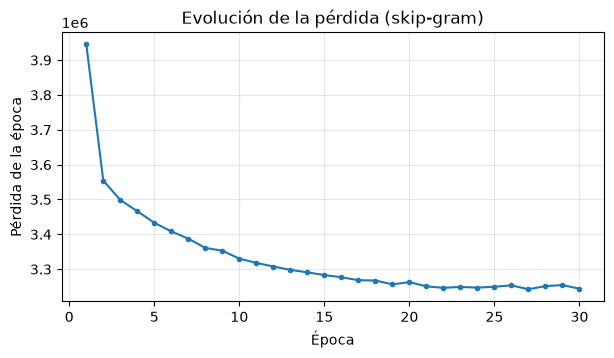

In [31]:
w2v_model = Word2Vec(min_count=5,      # frecuencia mínima de palabra para incluirla en el vocabulario
                     window=5,        # cantidad de palabras antes y después de la palabra central
                     vector_size=100, # dimensionalidad de los vectores
                     negative=10,     # cantidad de negative samples
                     sg=1,            # modelo 0: CBOW, 1: skip-gram
                     workers=1,       # un solo hilo para que el resultado sea reproducible
                     seed=SEED)

w2v_model.build_vocab(sentence_tokens)
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)
print("Cantidad de palabras en el vocabulario:", len(w2v_model.wv.index_to_key))

cb_sg = LossCallback()
w2v_model.train(sentence_tokens,
                total_examples=w2v_model.corpus_count,
                epochs=30,
                compute_loss=True,
                callbacks=[cb_sg])

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(cb_sg.losses) + 1), cb_sg.losses, marker="o", markersize=3)
plt.xlabel("Época")
plt.ylabel("Pérdida de la época")
plt.title("Evolución de la pérdida (skip-gram)")
plt.grid(alpha=0.3)
plt.show()

La pérdida cae fuertemente en las primeras épocas y a partir de la época 15 a 20 prácticamente se estabiliza. Esto indica que 30 épocas son suficientes y que agregar más no cambiaría de forma apreciable los vectores. El valor absoluto de la pérdida no es interpretable por sí mismo, porque es una suma sobre todos los pares (palabra, contexto) de la época. Lo útil es su tendencia.

## 4. Términos más similares

Elegí diez términos de interés: los dos protagonistas, Dulcinea, las dos cabalgaduras (Rocinante y el rucio de Sancho), los roles de caballero y escudero, la ínsula que se le promete a Sancho, un arma y uno de los personajes nobles de la segunda parte. Para cada uno busco las 8 palabras con mayor similaridad coseno.

In [32]:
def tabla_similares(model, palabras, topn=8):
    """Devuelve una tabla con las palabras más similares a cada término (similaridad coseno)."""
    columnas = {}
    for w in palabras:
        columnas[w] = [f"{p} ({s:.2f})" for p, s in model.wv.most_similar(positive=[w], topn=topn)]
    return pd.DataFrame(columnas, index=range(1, topn + 1))

terminos = ["quijote", "sancho", "dulcinea", "rocinante", "rucio",
            "caballero", "escudero", "ínsula", "espada", "duque"]

tabla_similares(w2v_model, terminos[:5])

,quijote,sancho,dulcinea,rocinante,rucio
1,don (0.77),panza (0.64),toboso (0.82),riendas (0.67),lío (0.62)
2,sancho (0.64),quijote (0.64),señora (0.64),espuelas (0.60),cabestro (0.60)
3,jerónimo (0.62),jerónimo (0.63),aldonza (0.61),cabestro (0.60),jumento (0.60)
4,oyólo (0.59),don (0.61),desencantar (0.60),caballo (0.59),asno (0.59)
5,álvaro (0.57),decid (0.61),desencanto (0.59),quitándole (0.58),picó (0.56)
6,cirongilio (0.54),teresa (0.59),transformada (0.58),seguíale (0.58),riendas (0.56)
7,caminante (0.54),hablas (0.58),desencantada (0.57),picó (0.58),encaminó (0.56)
8,tarfe (0.54),oyólo (0.56),par (0.56),embrazó (0.57),apeáronse (0.55)


In [33]:
tabla_similares(w2v_model, terminos[5:])

,caballero,escudero,ínsula,espada,duque
1,andante (0.70),panza (0.57),barataria (0.66),embrazó (0.63),canónigo (0.59)
2,aventurero (0.53),amo (0.54),posesión (0.60),rodela (0.61),cura (0.58)
3,hidalgo (0.53),sancho (0.53),gobierno (0.58),adarga (0.59),mayordomo (0.57)
4,caballería (0.51),venturoso (0.53),gobernar (0.56),embrazando (0.58),duquesa (0.57)
5,leones (0.51),martirios (0.51),andalucía (0.52),lanza (0.57),secretario (0.54)
6,ermitaño (0.50),cecial (0.50),prometida (0.51),arrimado (0.56),enviaba (0.53)
7,sabed (0.49),bravo (0.49),gobernador (0.51),brinco (0.55),licenciado (0.52)
8,leal (0.49),mentecato (0.48),diciplina (0.51),estribos (0.55),maestresala (0.52)


**Interpretación**

* **quijote**: su vecino más cercano es *don*, porque casi siempre aparece como "don Quijote". También aparecen su compañero *sancho* y otros nombres que suelen llevar "don" (*jerónimo*, *álvaro*, *tarfe*, por don Álvaro Tarfe). Incluso aparece *cirongilio*, por Cirongilio de Tracia, uno de los libros de caballerías que se mencionan en la obra. El vector refleja con quién y de qué forma se nombra al personaje.
* **sancho**: aparecen *panza*, *quijote*, *teresa* (Teresa Panza, su mujer) y expresiones de diálogo (*decid*, *hablas*). Esto es coherente con que Sancho participa en la mayoría de los diálogos de la obra.
* **dulcinea**: los resultados son muy precisos. *toboso* (Dulcinea del Toboso), *señora*, *aldonza* (su nombre real, Aldonza Lorenzo) y el vocabulario del encantamiento de la segunda parte (*desencantar*, *desencanto*, *transformada*, *desencantada*).
* **rocinante** y **rucio**: ambos se rodean de vocabulario de cabalgadura (*riendas*, *espuelas*, *cabestro*, *caballo*). En el caso del rucio aparecen sus sinónimos *jumento* y *asno*, lo que muestra que el modelo aprendió que se refieren al mismo tipo de animal.
* **caballero**: aparece *andante*, por la expresión "caballero andante", junto con *aventurero*, *hidalgo* y *caballería*. También aparece *leones*, por el sobrenombre "Caballero de los Leones".
* **escudero**: se asocia con *panza*, *amo* y *sancho*, es decir, con Sancho y su relación con don Quijote.
* **ínsula**: el vecindario describe la trama: *barataria*, *posesión*, *gobierno*, *gobernar*, *prometida*, *gobernador*.
* **espada**: aparecen otras armas (*adarga*, *rodela*, *lanza*) y verbos asociados a su uso (*embrazó*, *embrazando*, *arrimado*).
* **duque**: aparecen *duquesa* y otros personajes con cargo u oficio, varios de ellos de la casa ducal (*mayordomo*, *secretario*, *maestresala*), además de *canónigo*, *cura* y *licenciado*.

En general, los vecinos más cercanos son coherentes con el contenido de la obra. Algunos resultados mezclan palabras poco relacionadas (por ejemplo, formas verbales sueltas como *oyólo* o *quitándole*), lo que es esperable con un corpus de este tamaño.

## 5. Términos menos similares

Con `most_similar(negative=[...])` se buscan las palabras cuya dirección es más opuesta a la del término, es decir, con menor similaridad coseno.

In [34]:
def tabla_menos_similares(model, palabras, topn=8):
    """Palabras cuya dirección es más opuesta al término (most_similar con negative)."""
    columnas = {}
    for w in palabras:
        columnas[w] = [f"{p} ({s:.2f})" for p, s in model.wv.most_similar(negative=[w], topn=topn)]
    return pd.DataFrame(columnas, index=range(1, topn + 1))

tabla_menos_similares(w2v_model, ["caballero", "dulcinea", "espada", "amor"])

,caballero,dulcinea,espada,amor
1,alforjas (0.09),demasiado (0.10),quedaban (0.09),venían (0.07)
2,respuesta (0.06),algo (0.06),sucedido (0.09),arriba (0.05)
3,echado (0.03),hicieron (0.06),acontecido (0.07),dándole (0.05)
4,entena (0.03),sosegada (0.05),aquello (0.07),pelota (0.04)
5,repuesto (0.03),perro (0.05),peores (0.06),sentaron (0.04)
6,quita (0.02),pagó (0.05),despierto (0.04),vender (0.04)
7,músicas (0.02),mancebo (0.04),república (0.04),atentamente (0.04)
8,caídos (0.01),coge (0.04),gobierno (0.04),convenía (0.04)


**Interpretación**

Los valores de similaridad de las palabras "menos similares" son cercanos a 0 (todos menores a 0,10) y las listas mezclan palabras sin relación evidente entre sí. Esto se debe a que Word2Vec **no aprende opuestos semánticos**: una similaridad cercana a cero significa que las palabras no comparten contextos, no que tengan significados contrarios. De hecho, los antónimos suelen tener vectores parecidos porque aparecen en contextos similares (por ejemplo, *bueno* y *malo*).

Por eso, para analizar la falta de relación entre palabras resulta más informativo comparar pares concretos.

In [35]:
# Similaridad coseno entre pares de palabras con relación esperable y sin ella
pares = [("quijote", "sancho"), ("rocinante", "rucio"), ("caballero", "escudero"),
         ("dulcinea", "toboso"), ("espada", "lanza"),
         ("rocinante", "ínsula"), ("dulcinea", "espada"), ("caballero", "jumento")]

pd.DataFrame([(a, b, round(float(w2v_model.wv.similarity(a, b)), 3)) for a, b in pares],
             columns=["palabra 1", "palabra 2", "similaridad coseno"])

,palabra 1,palabra 2,similaridad coseno
0,quijote,sancho,0.639
1,rocinante,rucio,0.554
2,caballero,escudero,0.470
3,dulcinea,toboso,0.819
4,espada,lanza,0.575
5,rocinante,ínsula,0.133
6,dulcinea,espada,0.242
7,caballero,jumento,0.192


Los pares con relación esperable (los dos protagonistas, las dos cabalgaduras, caballero/escudero, Dulcinea/Toboso, espada/lanza) tienen similaridades claramente mayores que los pares sin relación (Rocinante/ínsula, Dulcinea/espada, caballero/jumento). Esto confirma que la similaridad coseno separa bien palabras relacionadas de palabras no relacionadas.

### Analogías y término que no corresponde

Como prueba adicional, evalúo algunas analogías mediante aritmética de vectores y la función `doesnt_match`, que busca el término más alejado del promedio de un grupo.

In [36]:
# Analogías del tipo "a es a b como c es a ?"  ->  b - a + c
def analogia(model, a, b, c, topn=5):
    res = model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    return [f"{p} ({s:.2f})" for p, s in res]

print("hombre : rey :: mujer : ?       ", analogia(w2v_model, "hombre", "rey", "mujer"))
print("caballero : caballo :: escudero : ?", analogia(w2v_model, "caballero", "caballo", "escudero"))
print("quijote : dulcinea :: sancho : ?   ", analogia(w2v_model, "quijote", "dulcinea", "sancho"))

# Término que no corresponde al grupo
print("\nNo corresponde en [rocinante, rucio, jumento, espada]:",
      w2v_model.wv.doesnt_match(["rocinante", "rucio", "jumento", "espada"]))
print("No corresponde en [cura, barbero, duque, lanza]:",
      w2v_model.wv.doesnt_match(["cura", "barbero", "duque", "lanza"]))

hombre : rey :: mujer : ?        ['legítima (0.48)', 'lobos (0.46)', 'riquezas (0.45)', 'perseguida (0.45)', 'vientre (0.45)']
caballero : caballo :: escudero : ? ['jumento (0.50)', 'seguíale (0.47)', 'lío (0.47)', 'albarda (0.46)', 'picó (0.46)']
quijote : dulcinea :: sancho : ?    ['toboso (0.64)', 'señora (0.57)', 'teresa (0.52)', 'enviar (0.48)', 'conocí (0.47)']

No corresponde en [rocinante, rucio, jumento, espada]: espada
No corresponde en [cura, barbero, duque, lanza]: lanza


**Interpretación**

* **hombre : rey :: mujer : ?** no devuelve *reina*. Es la analogía clásica de Word2Vec, pero en este corpus *rey* y *reina* aparecen en pocos contextos comparables, y la relación de género no queda codificada de forma consistente.
* **caballero : caballo :: escudero : ?** devuelve *jumento* en primer lugar. El modelo captura que el caballero monta a caballo y el escudero monta un jumento (el rucio de Sancho).
* **quijote : dulcinea :: sancho : ?** devuelve primero *toboso* y *señora*, que están muy cerca de *dulcinea* y "arrastran" el resultado. En tercer lugar aparece *teresa*, la mujer de Sancho, que es la respuesta esperable.
* `doesnt_match` identifica correctamente el término ajeno en ambos casos: *espada* entre cabalgaduras y *lanza* entre personajes.

Las analogías funcionan solo en algunos casos. Esto es esperable: este tipo de regularidades suele requerir corpus de millones de palabras.

## 6. Experimento: skip-gram vs. CBOW

Entreno un segundo modelo con los mismos hiperparámetros pero con arquitectura CBOW (`sg=0`) y comparo los vecinos de algunos términos.

In [37]:
w2v_cbow = Word2Vec(min_count=5, window=5, vector_size=100, negative=10,
                    sg=0,            # CBOW
                    workers=1, seed=SEED)
w2v_cbow.build_vocab(sentence_tokens)
w2v_cbow.train(sentence_tokens, total_examples=w2v_cbow.corpus_count, epochs=30)

comparar = ["quijote", "rocinante", "duque", "espada"]
pd.concat({"skip-gram": tabla_similares(w2v_model, comparar, topn=6),
           "CBOW": tabla_similares(w2v_cbow, comparar, topn=6)}, axis=1)

skip-gram                                                           \
             quijote          rocinante              duque             espada   
1         don (0.77)     riendas (0.67)    canónigo (0.59)     embrazó (0.63)   
2      sancho (0.64)    espuelas (0.60)        cura (0.58)      rodela (0.61)   
3    jerónimo (0.62)    cabestro (0.60)   mayordomo (0.57)      adarga (0.59)   
4       oyólo (0.59)     caballo (0.59)     duquesa (0.57)  embrazando (0.58)   
5      álvaro (0.57)  quitándole (0.58)  secretario (0.54)       lanza (0.57)   
6  cirongilio (0.54)    seguíale (0.58)     enviaba (0.53)    arrimado (0.56)   

              CBOW                                                      
           quijote        rocinante              duque          espada  
1  jerónimo (0.70)     rucio (0.63)       oidor (0.62)    lanza (0.73)  
2   antonio (0.64)  cabestro (0.61)    canónigo (0.61)   adarga (0.72)  
3      luis (0.61)     subir (0.61)    visorrey (0.60)     mano (0.70)  
4    álvaro (0.60)   jumento (0.60)        cura (0.59)   rodela (0.69)  
5  gregorio (0.59)   riendas (0.60)     ventero (0.58)  derecha (0.68)  
6   lorenzo (0.59)    rienda (0.57)  licenciado (0.56)    silla (0.63)

**Interpretación**

Las dos arquitecturas capturan relaciones de distinto tipo:

* **Skip-gram** tiende a agrupar palabras que **aparecen juntas** en el texto (relación sintagmática). *rocinante* se asocia con *riendas* y *espuelas*, y *quijote* con *don*.
* **CBOW** tiende a agrupar palabras que **pueden ocupar el mismo lugar** en una oración (relación paradigmática). *quijote* se asocia con otros nombres propios (*jerónimo*, *antonio*, *luis*, *gregorio*), *rocinante* con las otras cabalgaduras (*rucio*, *jumento*) y *duque* con otros cargos (*oidor*, *canónigo*, *visorrey*, *ventero*).

En el caso de *espada* ambos modelos coinciden en asociarla con otras armas (*lanza*, *adarga*, *rodela*). La diferencia no es absoluta: en los dos modelos aparecen ambos tipos de relación, pero con distinto peso.

Para el objetivo de este trabajo, que es ver cómo se usan las palabras dentro de la obra, el modelo skip-gram resulta más informativo porque sus vecinos reflejan los temas y escenas del libro. Por eso continúo con él.

## 7. Reducción de dimensionalidad y visualización

Para proyectar los vectores a 2 dimensiones uso t-SNE. Decisiones tomadas:

* **Selección de palabras**: si se toman directamente las palabras más frecuentes, el gráfico queda dominado por artículos, preposiciones y pronombres. Por eso tomo las más frecuentes **excluyendo stopwords** (lista de spaCy para español más algunas formas antiguas y muletillas del texto, como *desta*, *agora*, *vuesa merced*).
* **t-SNE solo sobre las palabras graficadas**: así la proyección conserva los vecinos entre las palabras que efectivamente se muestran.
* **`perplexity=15`**: este parámetro indica aproximadamente cuántos vecinos considera t-SNE para cada punto. Con 150 palabras, un valor bajo favorece la formación de grupos locales chicos, que es lo que se busca observar.
* **`init="pca"` y `random_state=0`**: hacen que la proyección sea más estable y reproducible.

Primero pruebo con 400 palabras:

In [38]:
# Se grafican las palabras más frecuentes del vocabulario, excluyendo stopwords
# (artículos, preposiciones, pronombres), que no aportan agrupaciones interpretables.
# Se agregan algunas formas antiguas muy frecuentes en el texto que spaCy no incluye.
STOP_EXTRA = {"dijo", "vuestra", "merced", "cosa", "cosas", "pues", "aunque", "así",
              "hacer", "dél", "della", "dellos", "ansí", "quien", "señor", "don", "ser",
              "ha", "he", "han", "habían", "tan", "otro", "otra", "otros", "puesto",
              "desta", "deste", "destos", "vuesa", "mesmo", "mesma", "agora", "tales",
              "tanta", "tantas", "has", "habéis", "jamás", "finalmente", "vos"}
stop = STOP_WORDS | STOP_EXTRA

def palabras_a_graficar(model, n):
    return [w for w in model.wv.index_to_key if w not in stop and len(w) > 2][:n]

def proyectar_2d(model, palabras):
    vectores = np.asarray([model.wv[w] for w in palabras])
    tsne = TSNE(n_components=2, perplexity=15, random_state=0, init="pca")
    return tsne.fit_transform(vectores)

def graficar(coords, palabras, titulo, figsize=(14, 10), fontsize=9):
    plt.figure(figsize=figsize)
    plt.scatter(coords[:, 0], coords[:, 1], s=8, alpha=0.6)
    for (x, y), w in zip(coords, palabras):
        plt.annotate(w, (x, y), fontsize=fontsize, alpha=0.85,
                     xytext=(2, 2), textcoords="offset points")
    plt.title(titulo)
    plt.xticks([]); plt.yticks([])
    plt.tight_layout()

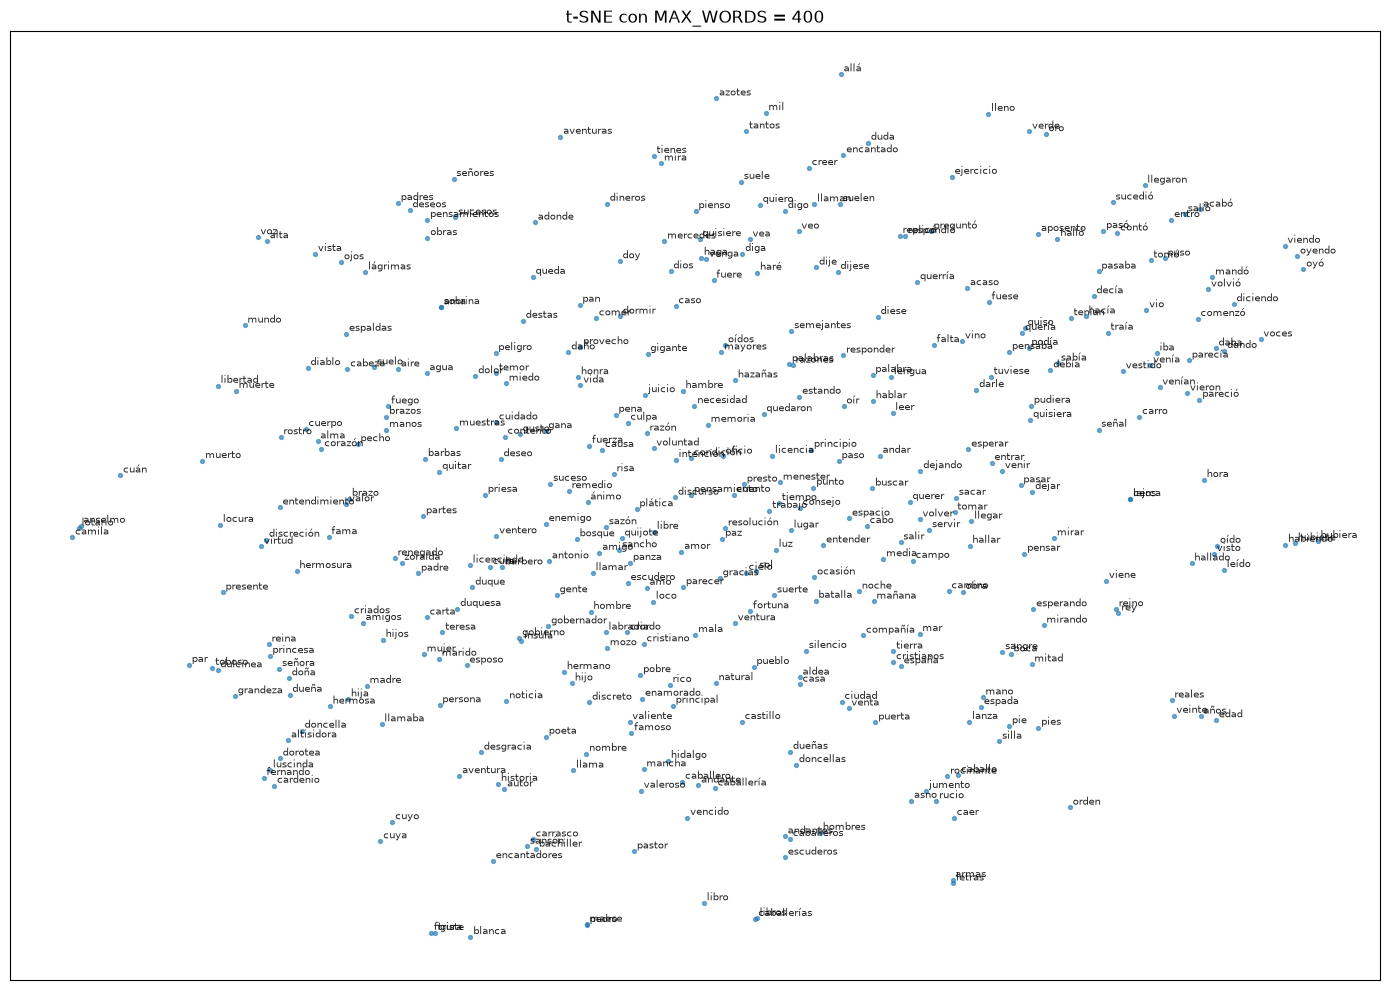

In [39]:
# Primera prueba: 400 palabras
palabras_400 = palabras_a_graficar(w2v_model, 400)
coords_400 = proyectar_2d(w2v_model, palabras_400)
graficar(coords_400, palabras_400, "t-SNE con MAX_WORDS = 400", fontsize=7)
plt.show()

Con 400 palabras las etiquetas se superponen en muchas zonas y el gráfico es difícil de leer, aunque ya se distinguen algunos grupos. Reduzco la cantidad a **`MAX_WORDS = 150`**. Con este valor las etiquetas son legibles y se siguen incluyendo los personajes y temas principales de la obra.

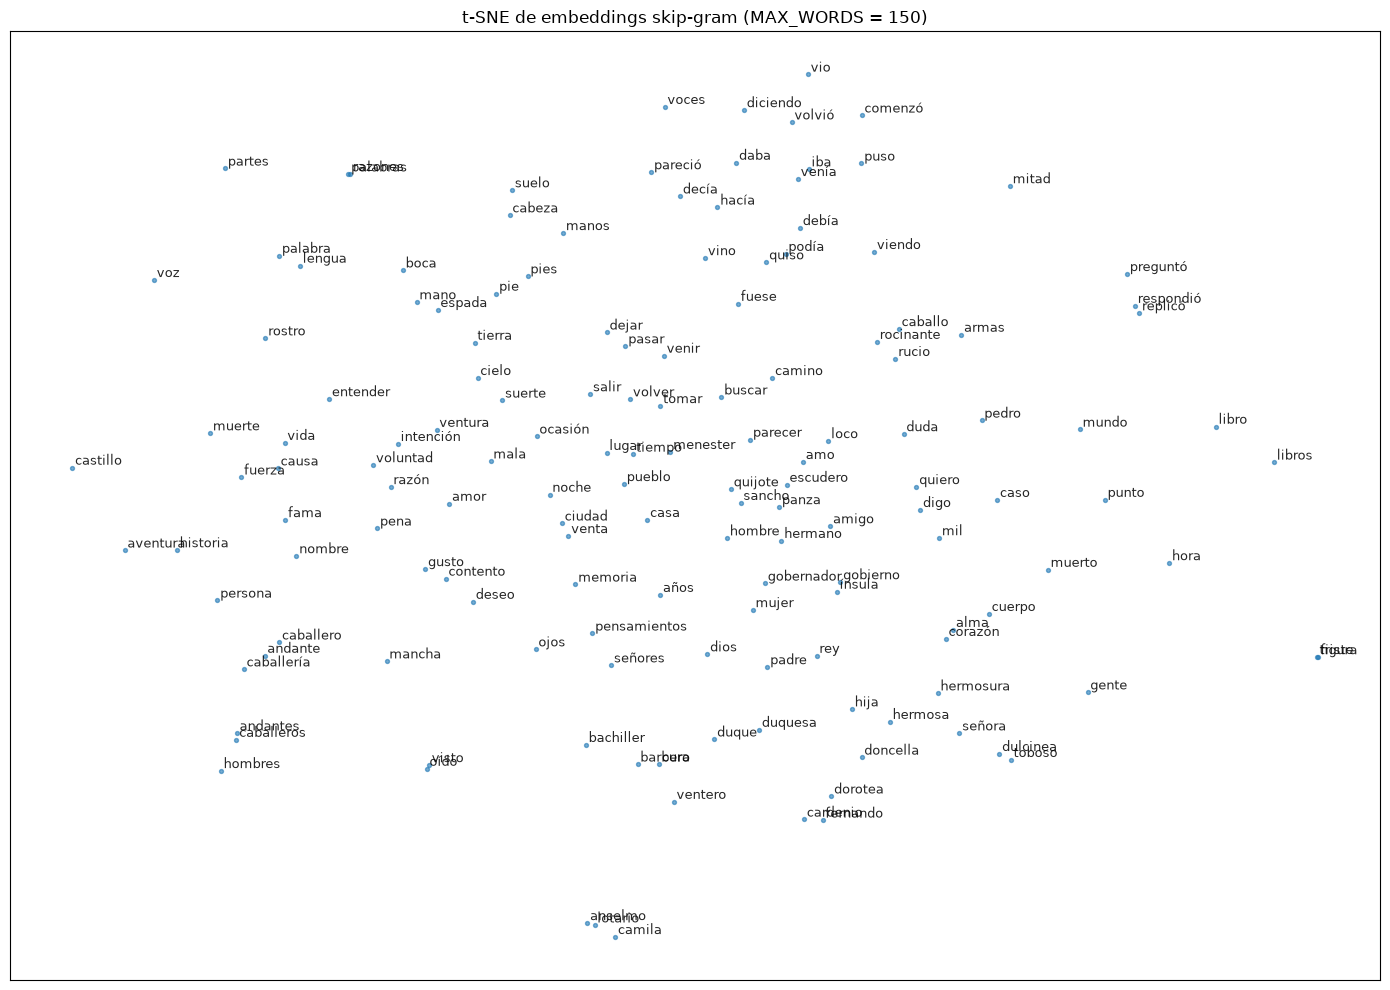

In [40]:
MAX_WORDS = 150

palabras = palabras_a_graficar(w2v_model, MAX_WORDS)
coords = proyectar_2d(w2v_model, palabras)
graficar(coords, palabras, f"t-SNE de embeddings skip-gram (MAX_WORDS = {MAX_WORDS})")
os.makedirs("img", exist_ok=True)
plt.savefig(os.path.join("img", "tsne_150.png"), dpi=110)
plt.show()

In [41]:
# Versión interactiva del mismo gráfico (permite hacer zoom y leer cada etiqueta)
import plotly.express as px

fig = px.scatter(x=coords[:, 0], y=coords[:, 1], text=palabras, width=950, height=700)
fig.update_traces(textposition="top center", marker_size=4)
fig.show()

## 8. Grupos de palabras observados

Inspeccionando el gráfico identifiqué los siguientes grupos. Para cada uno grafico la zona correspondiente del plano, con las palabras del grupo en rojo y el resto en gris. Las imágenes se guardan en la carpeta `img/` y se incluyen como capturas en las celdas de texto.

In [42]:
def zoom_grupo(coords, palabras, grupo, titulo, archivo, margen=2.0, ventana_min=12.0):
    """Grafica la región del plano que contiene al grupo y resalta sus palabras.

    La ventana tiene un tamaño mínimo para que los grupos muy compactos se vean
    junto a su entorno y no se exageren las distancias internas.
    """
    idx = [palabras.index(w) for w in grupo]
    centro = (coords[idx].min(axis=0) + coords[idx].max(axis=0)) / 2
    mitad = np.maximum((coords[idx].max(axis=0) - coords[idx].min(axis=0)) / 2 + margen,
                       ventana_min / 2)
    xmin, ymin = centro - mitad
    xmax, ymax = centro + mitad
    plt.figure(figsize=(6, 4.5))
    for (x, y), w in zip(coords, palabras):
        if xmin <= x <= xmax and ymin <= y <= ymax:
            color = "tab:red" if w in grupo else "tab:gray"
            plt.scatter(x, y, s=12, color=color)
            plt.annotate(w, (x, y), fontsize=10, color=color,
                         xytext=(2, 2), textcoords="offset points")
    plt.xlim(xmin, xmax + 0.15 * (xmax - xmin))   # espacio extra a la derecha para las etiquetas
    plt.ylim(ymin, ymax)
    plt.title(titulo)
    plt.xticks([]); plt.yticks([])
    plt.tight_layout()
    plt.savefig(os.path.join("img", archivo), dpi=110)
    plt.show()

### Los protagonistas y el gobierno de Sancho

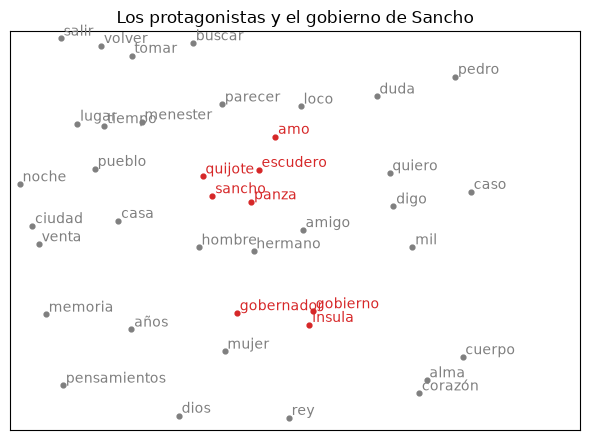

In [43]:
zoom_grupo(coords, palabras, ['quijote', 'sancho', 'panza', 'escudero', 'amo', 'gobernador', 'gobierno', 'ínsula'],
           'Los protagonistas y el gobierno de Sancho', 'grupo_protagonistas.png')

![Los protagonistas y el gobierno de Sancho](img/grupo_protagonistas.png)

En el centro del gráfico quedan juntos *quijote*, *sancho* y *panza*, rodeados por *escudero* y *amo*, que son los roles que cumplen uno respecto del otro. Muy cerca aparecen *gobernador*, *gobierno* e *ínsula*. Esto corresponde a la promesa de la ínsula y al episodio de Sancho como gobernador de Barataria. El grupo de gobierno queda próximo a Sancho porque es la trama en la que él es protagonista.

### Las cabalgaduras

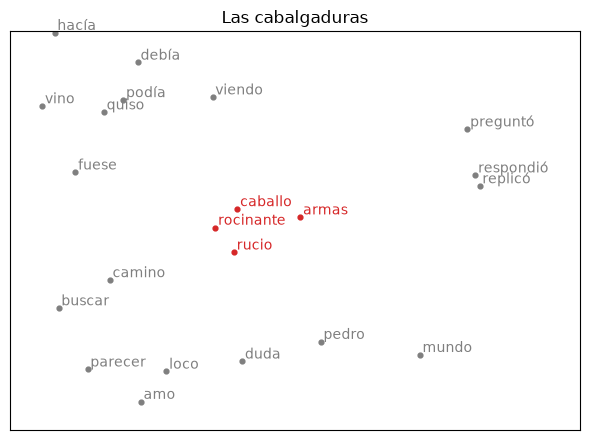

In [44]:
zoom_grupo(coords, palabras, ['rocinante', 'rucio', 'caballo', 'armas'],
           'Las cabalgaduras', 'grupo_cabalgaduras.png')

![Las cabalgaduras](img/grupo_cabalgaduras.png)

*rocinante*, *rucio* y *caballo* forman un grupo compacto junto con *armas*. Es el vocabulario de las salidas de don Quijote y Sancho: montar, armarse, ponerse en camino. Es coherente con los vecinos de *rocinante* y *rucio* de la sección 4.

### Partes del cuerpo y la espada

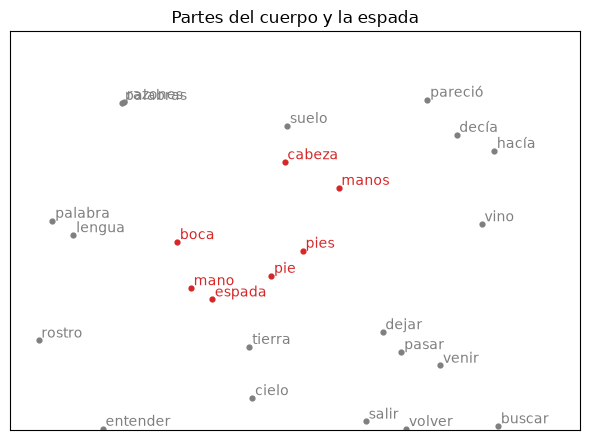

In [45]:
zoom_grupo(coords, palabras, ['mano', 'manos', 'pie', 'pies', 'cabeza', 'boca', 'espada'],
           'Partes del cuerpo y la espada', 'grupo_cuerpo.png')

![Partes del cuerpo y la espada](img/grupo_cuerpo.png)

Las partes del cuerpo (*mano*, *manos*, *pie*, *pies*, *cabeza*, *boca*) forman una región común. *espada* queda pegada a *mano*, lo que refleja expresiones frecuentes como "la espada en la mano" o "puso mano a la espada". Este grupo corresponde a las descripciones físicas de las peleas y caídas.

### Personajes secundarios

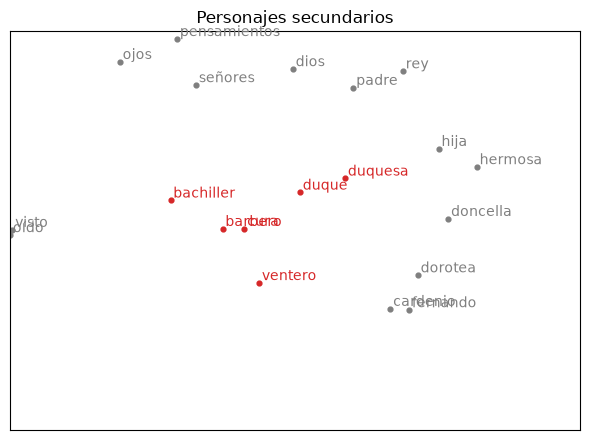

In [46]:
zoom_grupo(coords, palabras, ['cura', 'barbero', 'bachiller', 'ventero', 'duque', 'duquesa'],
           'Personajes secundarios', 'grupo_personajes.png')

![Personajes secundarios](img/grupo_personajes.png)

*cura*, *barbero* (prácticamente superpuestos), *bachiller* (Sansón Carrasco) y *ventero* son los personajes del pueblo y de las ventas que intentan devolver a don Quijote a su casa. Cerca aparecen *duque* y *duquesa*, los anfitriones de la segunda parte. Todos son personajes secundarios que interactúan con los protagonistas en escenas similares.

### El curioso impertinente

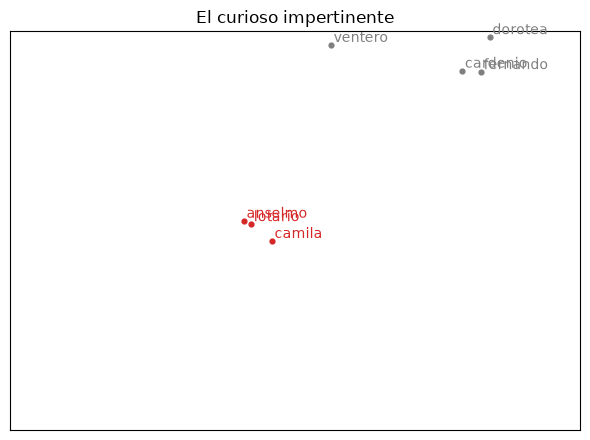

In [47]:
zoom_grupo(coords, palabras, ['anselmo', 'lotario', 'camila'],
           'El curioso impertinente', 'grupo_novela.png')

![El curioso impertinente](img/grupo_novela.png)

Este es el grupo más aislado del gráfico. *anselmo*, *lotario* y *camila* son los protagonistas de *El curioso impertinente*, una novela que se lee dentro de la primera parte. Como estos personajes aparecen casi exclusivamente en esos capítulos, comparten contextos entre sí y casi ninguno con el resto de la obra. Algo similar ocurre con *dorotea*, *cardenio* y *fernando*, personajes de la historia de Sierra Morena, que también quedan agrupados en la parte inferior del gráfico general.

### Verbos de diálogo

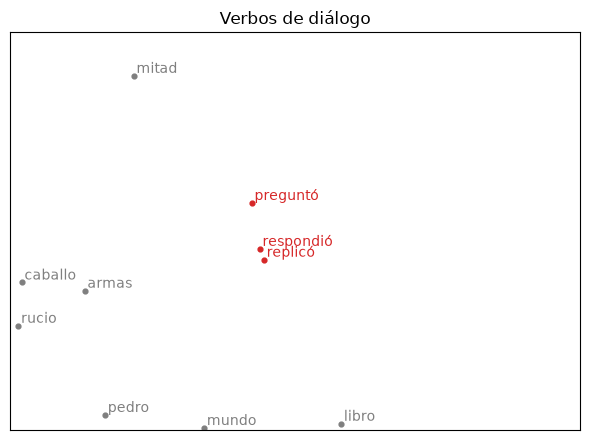

In [48]:
zoom_grupo(coords, palabras, ['respondió', 'replicó', 'preguntó'],
           'Verbos de diálogo', 'grupo_dialogo.png')

![Verbos de diálogo](img/grupo_dialogo.png)

*respondió*, *replicó* y *preguntó* quedan aislados en un extremo del gráfico. Son verbos de diálogo que aparecen en la misma posición de la oración ("—... —respondió Sancho"). Aquí la similitud es más **sintáctica** que temática.

### Dulcinea y el ideal femenino

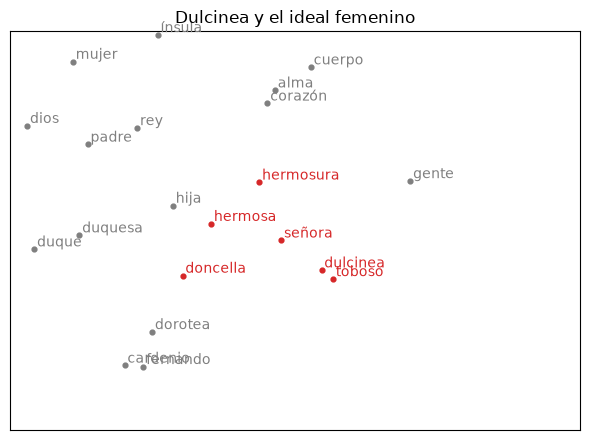

In [49]:
zoom_grupo(coords, palabras, ['dulcinea', 'toboso', 'señora', 'hermosa', 'hermosura', 'doncella'],
           'Dulcinea y el ideal femenino', 'grupo_dulcinea.png')

![Dulcinea y el ideal femenino](img/grupo_dulcinea.png)

*dulcinea*, *toboso* y *señora* quedan muy próximos ("mi señora Dulcinea del Toboso"). Cerca aparecen *hermosa*, *hermosura* y *doncella*, que es el vocabulario con el que don Quijote idealiza a su dama.

### Verbos en pretérito

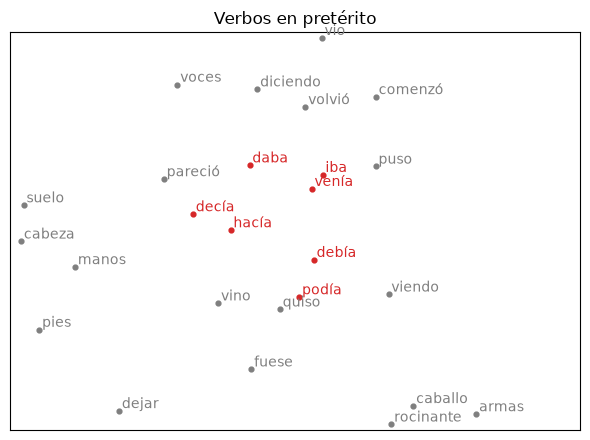

In [50]:
zoom_grupo(coords, palabras, ['podía', 'hacía', 'debía', 'venía', 'iba', 'daba', 'decía'],
           'Verbos en pretérito', 'grupo_preterito.png')

![Verbos en pretérito](img/grupo_preterito.png)

Verbos conjugados en pretérito imperfecto (*podía*, *hacía*, *debía*, *venía*, *iba*, *daba*, *decía*) forman una región común en la parte superior del gráfico, junto a otros verbos en pretérito (*vio*, *volvió*, *comenzó*, *puso*). Como en el grupo de diálogo, el agrupamiento se explica por la **función gramatical** y no por el significado: estas formas ocupan posiciones similares en la narración.

También se observan pares de palabras superpuestas que corresponden a expresiones fijas de la obra: *caballeros*/*andantes*, *triste*/*figura* (por "el Caballero de la Triste Figura"), *palabras*/*razones* y *visto*/*oído*. Estas palabras aparecen casi siempre juntas y por eso sus vectores son prácticamente iguales.

## 9. Conclusiones

* Con un corpus de unas 380 000 palabras, Word2Vec (skip-gram) aprende vectores que reflejan de forma coherente el contenido de *Don Quijote*. Los vecinos de los personajes, objetos y lugares coinciden con los episodios de la obra.
* Los vectores codifican **cómo se usa cada palabra en este texto en particular**, no su significado general. Por ejemplo, *quijote* queda cerca de *don* y *caballero* cerca de *leones*, asociaciones que solo tienen sentido dentro de la novela.
* La búsqueda de términos "menos similares" no devuelve opuestos semánticos, sino palabras sin relación (similaridad cercana a 0), porque Word2Vec solo modela coaparición de contextos.
* Las analogías funcionan solo en algunos casos (*caballero : caballo :: escudero : jumento*). Este tipo de relaciones suele requerir corpus mucho más grandes que el utilizado.
* Skip-gram y CBOW capturan relaciones distintas: skip-gram favorece asociaciones temáticas (palabras que aparecen juntas) y CBOW asociaciones por categoría (palabras intercambiables).
* En la proyección t-SNE aparecen dos tipos de grupos. Algunos son **temáticos**: los protagonistas y el gobierno de la ínsula, las cabalgaduras, las partes del cuerpo, los personajes secundarios, las novelas intercaladas y Dulcinea. Otros son **gramaticales**: los verbos de diálogo y los verbos en pretérito. Elegir `MAX_WORDS = 150` y excluir stopwords fue necesario para que estos grupos se puedan leer en el gráfico.